In [2]:
import keras
from keras.datasets import reuters
import numpy as np

(train_data, train_labels), (test_data, test_labels) = reuters.load_data(
    num_words=10000
)

def multihot_encode(sequences, num_classes):
    results = np.zeros((len(sequences), num_classes))
    for i, sequences in enumerate(sequences):
        results[i][sequences] = 1.0
    return results

x_train = multihot_encode(train_data, num_classes=10000)
x_test = multihot_encode(test_data, num_classes=10000)

In [3]:

def one_hot_encode(labels, num_classes=46):
    results = np.zeros((len(labels), num_classes))
    for i, label in enumerate(labels):
        results[i, label] = 1.0
    return results

y_train = one_hot_encode(train_labels)
y_test = one_hot_encode(test_labels)

In [4]:
# helper to do one-hot encoding in keras
from keras.utils import to_categorical
y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

In [5]:
model = keras.Sequential([
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(46, activation="softmax")
])

In [6]:
top3_acc = keras.metrics.TopKCategoricalAccuracy(
    k=3, name="top_3_accuracy"
)

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy", top3_acc]
)

In [7]:
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

In [8]:
history = model.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.4432 - loss: 3.3259 - top_3_accuracy: 0.5547 - val_accuracy: 0.5500 - val_loss: 2.5990 - val_top_3_accuracy: 0.6780
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6228 - loss: 2.0445 - top_3_accuracy: 0.7321 - val_accuracy: 0.6540 - val_loss: 1.6755 - val_top_3_accuracy: 0.7730
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7146 - loss: 1.3747 - top_3_accuracy: 0.8131 - val_accuracy: 0.7180 - val_loss: 1.3284 - val_top_3_accuracy: 0.8200
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7808 - loss: 1.0483 - top_3_accuracy: 0.8705 - val_accuracy: 0.7590 - val_loss: 1.1535 - val_top_3_accuracy: 0.8530
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8307 - loss: 0.8263 - top_3_accuracy: 0.9079 - val_accuracy: 0.7870 - val_loss: 1.0563 - val_top_3_accuracy: 0.8770
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8664 - loss: 0.6555 - top_3_ac

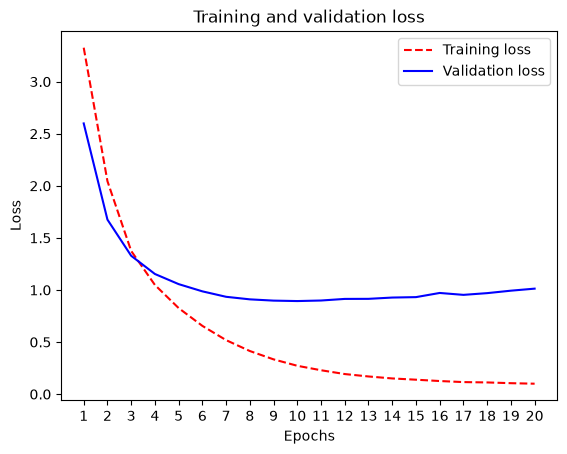

In [9]:
import matplotlib.pyplot as plt

loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

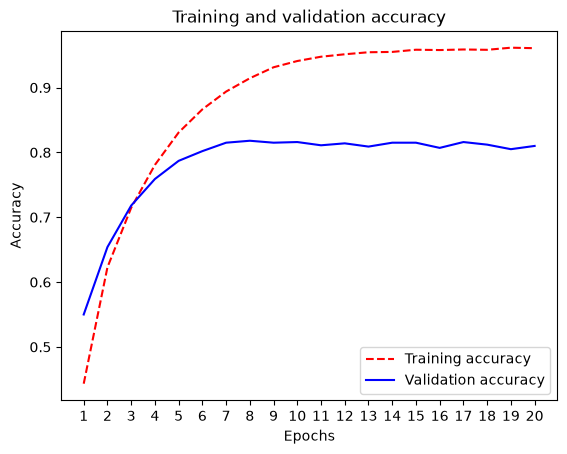

In [10]:
plt.clf()
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

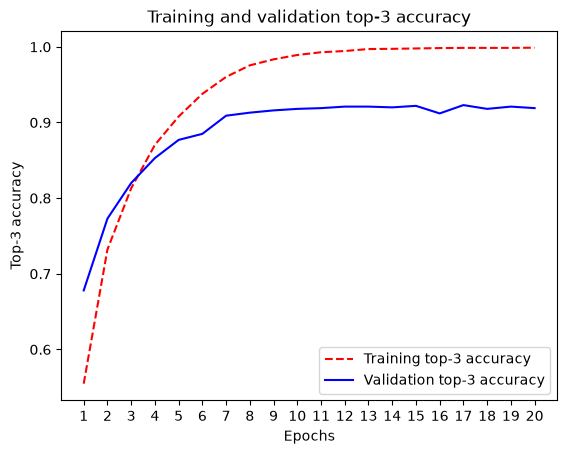

In [11]:
plt.clf()
acc = history.history["top_3_accuracy"]
val_acc = history.history["val_top_3_accuracy"]
plt.plot(epochs, acc, "r--", label="Training top-3 accuracy")
plt.plot(epochs, val_acc, "b", label="Validation top-3 accuracy")
plt.title("Training and validation top-3 accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Top-3 accuracy")
plt.legend()
plt.show()


In [12]:
predictions = model.predict(x_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step   


In [16]:
np.argmax(predictions[0])

np.int64(3)